In [19]:
from typing import TypedDict



class PortfolioState(TypedDict):
    amount_usd: float
    total_usd_after_interest: float
    total_inr: float

In [20]:
my_obj : PortfolioState = PortfolioState({"amount_usd": 33.33, "total_usd_after_interest": 40.00})
my_obj

{'amount_usd': 33.33, 'total_usd_after_interest': 40.0}

In [21]:
def calculate_total_usd(state: PortfolioState) -> PortfolioState:
    state["total_usd_after_interest"] = state["amount_usd"] * 1.08
    return state


def calculate_total_inr(state: PortfolioState) -> PortfolioState:
    exchange_rate = 94.94
    state["total_inr"] = state["total_usd_after_interest"] * exchange_rate
    return state


In [22]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PortfolioState)
builder.add_node("calculate_total_usd_node", calculate_total_usd)
builder.add_node("calculate_total_inr_node", calculate_total_inr)

builder.add_edge(START, "calculate_total_usd_node")
builder.add_edge("calculate_total_usd_node", "calculate_total_inr_node")
builder.add_edge("calculate_total_inr_node", END)

graph = builder.compile()


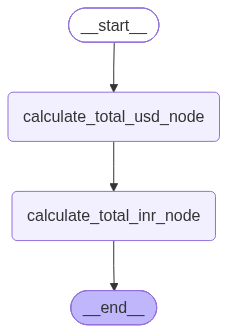

In [23]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
graph.invoke({"amount_usd": 100})

{'amount_usd': 100, 'total_usd_after_interest': 108.0, 'total_inr': 10253.52}